# Анализ влияния погодных условий на задержки рейсов

## Цель исследования

Определить, существует ли связь между погодными условиями в аэропорту Пхукета (HKT) и задержками рейсов.

## Исследовательские вопросы

1. Влияет ли скорость ветра на задержки рейсов?
2. Влияют ли осадки на задержки рейсов?
3. Влияет ли видимость на пунктуальность рейсов?
4. Какие погодные факторы оказывают наибольшее влияние?
5. Является ли обнаруженная связь статистически значимой?

In [1]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
import seaborn as sns

## Подключение к базе данных

In [2]:
from db import get_engine

In [3]:
engine = get_engine()

In [4]:
query = """
SELECT current_database()
"""

pd.read_sql(query, engine)

,current_database
0,flight


## Загрузка данных

In [5]:
query = """
SELECT *
FROM analytics_marts.mart_weather_flight_impact
"""

weather_df = pd.read_sql(query, engine)
weather_df.head()

,weather_key,weather_time_utc,weather_date,weather_hour,weather_day_of_week,operation_type,temperature_2m_c,apparent_temperature_c,dewpoint_2m_c,relative_humidity_2m_pct,...,is_low_visibility,total_operations,avg_delay_minutes,avg_positive_delay_minutes,delayed_operations,minor_delay_operations,ontime_operations,unknown_operations,delay_rate,ontime_rate
0,0053fa77b2208b581e44fb116acad471,2025-12-01 13:00:00,2025-12-01,13,Monday,arrival,27.7,32.5,23.1,76.0,...,False,13,4.38,24.14,2,5,6,0,0.1538,0.4615
1,0053fa77b2208b581e44fb116acad471,2025-12-01 13:00:00,2025-12-01,13,Monday,departure,27.7,32.5,23.1,76.0,...,False,9,19.67,25.29,2,5,2,0,0.2222,0.2222
2,00bbaf45fd64fff3fdd3ad455f083d4b,2025-11-22 11:00:00,2025-11-22,11,Saturday,arrival,26.1,31.1,23.8,87.0,...,False,10,18.00,28.86,4,3,3,0,0.4000,0.3000
3,00bbaf45fd64fff3fdd3ad455f083d4b,2025-11-22 11:00:00,2025-11-22,11,Saturday,departure,26.1,31.1,23.8,87.0,...,False,10,27.50,43.86,5,2,3,0,0.5000,0.3000
4,014ab9c75f4ea575733498679eec3859,2025-12-15 16:00:00,2025-12-15,16,Monday,arrival,26.6,31.5,23.7,84.0,...,False,8,1.75,14.67,1,2,5,0,0.1250,0.6250


In [6]:
weather_df.shape

(1763, 40)

In [7]:
weather_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1763 entries, 0 to 1762
Data columns (total 40 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   weather_key                 1763 non-null   str           
 1   weather_time_utc            1763 non-null   datetime64[us]
 2   weather_date                1763 non-null   object        
 3   weather_hour                1763 non-null   int64         
 4   weather_day_of_week         1763 non-null   str           
 5   operation_type              1763 non-null   str           
 6   temperature_2m_c            1763 non-null   float64       
 7   apparent_temperature_c      1763 non-null   float64       
 8   dewpoint_2m_c               1763 non-null   float64       
 9   relative_humidity_2m_pct    1763 non-null   float64       
 10  precipitation_mm            1763 non-null   float64       
 11  rain_mm                     1763 non-null   float64       
 12  sno

In [8]:
weather_df.describe()

,weather_time_utc,weather_hour,temperature_2m_c,apparent_temperature_c,dewpoint_2m_c,relative_humidity_2m_pct,precipitation_mm,rain_mm,snowfall_cm,cloudcover_pct,...,weathercode,total_operations,avg_delay_minutes,avg_positive_delay_minutes,delayed_operations,minor_delay_operations,ontime_operations,unknown_operations,delay_rate,ontime_rate
count,1763,1763.000000,1763.000000,1763.000000,1763.000000,1763.000000,1763.000000,1763.000000,1763.0,1763.000000,...,1763.000000,1763.000000,1763.000000,1633.000000,1763.000000,1763.000000,1763.000000,1763.0,1763.000000,1763.000000
mean,2026-01-11 21:59:08.950652,9.475326,27.763471,32.580771,23.376007,77.562110,0.151333,0.010153,0.0,72.228020,...,14.594441,8.866137,16.107799,33.246326,2.946115,2.319909,3.600113,0.0,0.314953,0.434536
min,2025-11-21 10:00:00,0.000000,23.600000,26.200000,19.000000,46.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,-38.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
25%,2025-12-03 00:30:00,4.000000,26.600000,31.300000,22.800000,72.000000,0.000000,0.000000,0.0,49.000000,...,2.000000,8.000000,4.000000,17.500000,1.000000,1.000000,2.000000,0.0,0.153800,0.250000
50%,2025-12-14 13:00:00,9.000000,27.600000,32.500000,23.600000,79.000000,0.000000,0.000000,0.0,82.000000,...,3.000000,10.000000,12.080000,26.710000,3.000000,2.000000,3.000000,0.0,0.307700,0.416700
75%,2025-12-25 10:30:00,14.000000,28.800000,33.700000,24.100000,84.000000,0.000000,0.000000,0.0,100.000000,...,3.000000,11.000000,22.130000,39.670000,4.000000,4.000000,5.000000,0.0,0.454500,0.571400
max,2026-10-05 17:00:00,23.000000,32.000000,39.800000,26.600000,96.000000,7.000000,2.200000,0.0,100.000000,...,96.000000,16.000000,634.000000,634.000000,12.000000,9.000000,13.000000,0.0,1.000000,1.000000
std,NaN,5.901945,1.568447,1.929083,1.121515,8.862871,0.516902,0.093209,0.0,29.346247,...,28.524309,3.380220,27.660207,32.311379,2.107750,1.724757,2.208368,0.0,0.216412,0.258485


## Корреляционный анализ

Корреляция показывает только наличие статистической связи между признаками. Наличие корреляции не означает наличие причинно-следственной зависимости. Поэтому результаты данного этапа следует рассматривать как предварительные выводы, которые впоследствии могут быть дополнительно проверены с помощью статистических тестов.

In [9]:
corr_df = weather_df.loc[:, [
                            'has_thunderstorm',
                            'rain_mm',
                            'visibility_m',
                            'cloudcover_pct',
                            'windspeed_10m_ms',
                            'delay_rate',
                            'avg_delay_minutes'
                        ]
    ]
corr_df.head()

,has_thunderstorm,rain_mm,visibility_m,cloudcover_pct,windspeed_10m_ms,delay_rate,avg_delay_minutes
0,False,0.0,24140.0,43.0,5.2,0.1538,4.38
1,False,0.0,24140.0,43.0,5.2,0.2222,19.67
2,False,0.0,19580.0,100.0,6.8,0.4000,18.00
3,False,0.0,19580.0,100.0,6.8,0.5000,27.50
4,False,0.0,24140.0,100.0,7.3,0.1250,1.75


In [10]:
corr_matrix = corr_df.corr(numeric_only=True)
corr_matrix

,has_thunderstorm,rain_mm,visibility_m,cloudcover_pct,windspeed_10m_ms,delay_rate,avg_delay_minutes
has_thunderstorm,1.000000,0.030930,-0.322198,0.175959,-0.029217,0.095023,0.026117
rain_mm,0.030930,1.000000,-0.192549,0.081897,0.011201,-0.043895,-0.039142
visibility_m,-0.322198,-0.192549,1.000000,-0.184485,0.002167,0.078785,0.062630
cloudcover_pct,0.175959,0.081897,-0.184485,1.000000,0.067267,0.094653,0.066476
windspeed_10m_ms,-0.029217,0.011201,0.002167,0.067267,1.000000,0.061660,0.034260
delay_rate,0.095023,-0.043895,0.078785,0.094653,0.061660,1.000000,0.566938
avg_delay_minutes,0.026117,-0.039142,0.062630,0.066476,0.034260,0.566938,1.000000


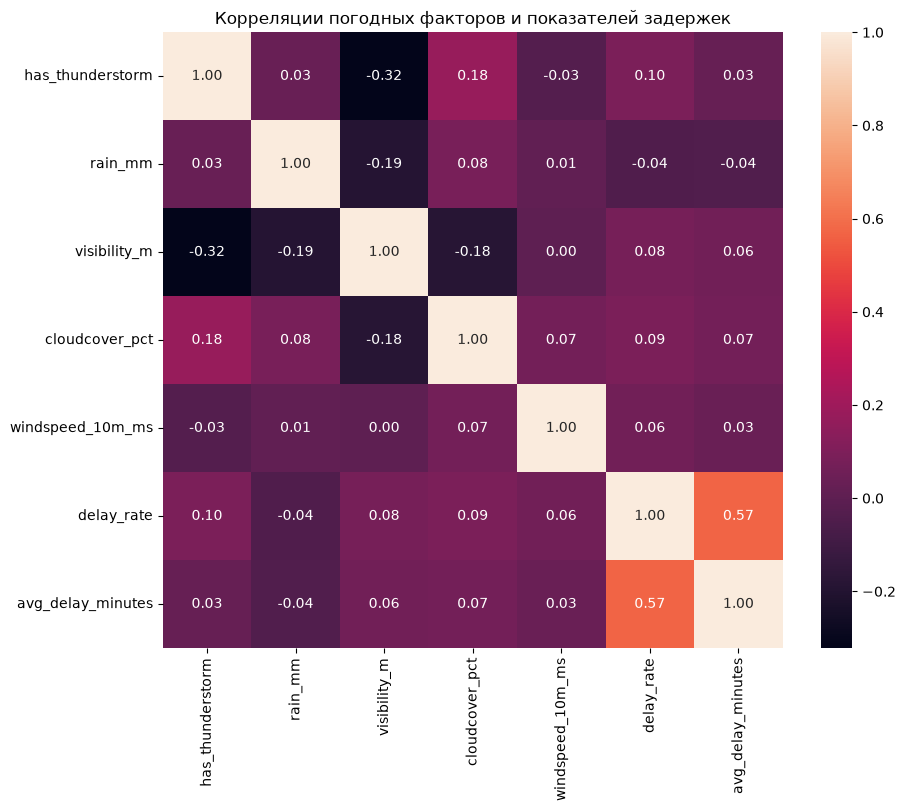

In [11]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f'
)

plt.title('Корреляции погодных факторов и показателей задержек')
plt.show()

<Figure size 1000x600 with 0 Axes>

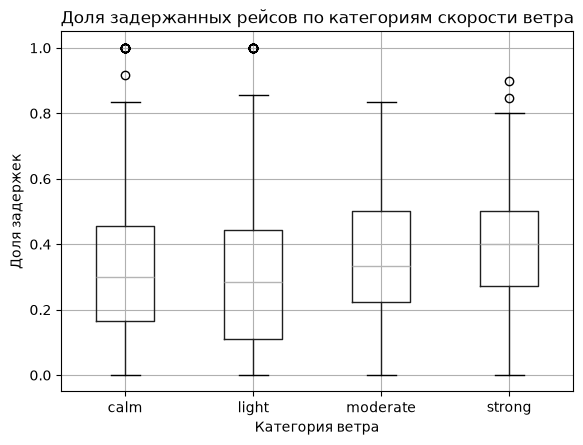

In [12]:
plt.figure(figsize=(10, 6))

weather_df.boxplot(
    column='delay_rate',
    by='wind_category'
)

plt.title('Доля задержанных рейсов по категориям скорости ветра')
plt.suptitle('')
plt.xlabel('Категория ветра')
plt.ylabel('Доля задержек')

plt.show()

<Figure size 1000x600 with 0 Axes>

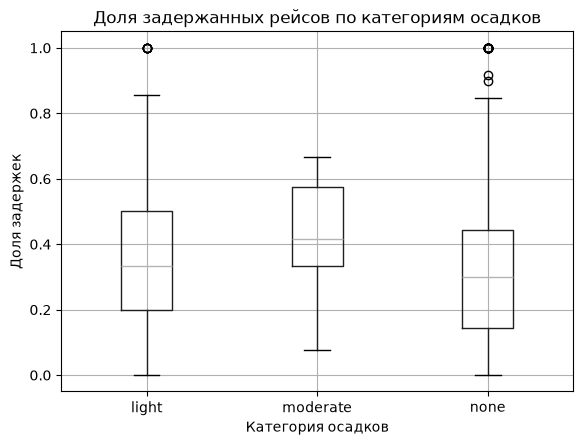

In [13]:
plt.figure(figsize=(10, 6))

weather_df.boxplot(
    column='delay_rate',
    by='precipitation_category'
)

plt.title('Доля задержанных рейсов по категориям осадков')
plt.suptitle('')
plt.xlabel('Категория осадков')
plt.ylabel('Доля задержек')

plt.show()

<Figure size 1000x600 with 0 Axes>

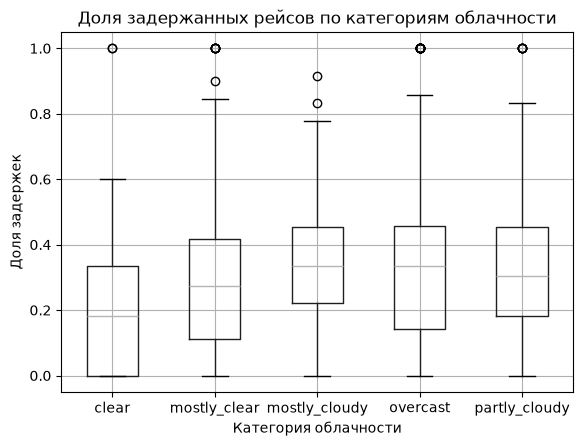

In [14]:
plt.figure(figsize=(10, 6))

weather_df.boxplot(
    column='delay_rate',
    by='cloudcover_category'
)

plt.title('Доля задержанных рейсов по категориям облачности')
plt.suptitle('')
plt.xlabel('Категория облачности')
plt.ylabel('Доля задержек')

plt.show()

<Figure size 800x600 with 0 Axes>

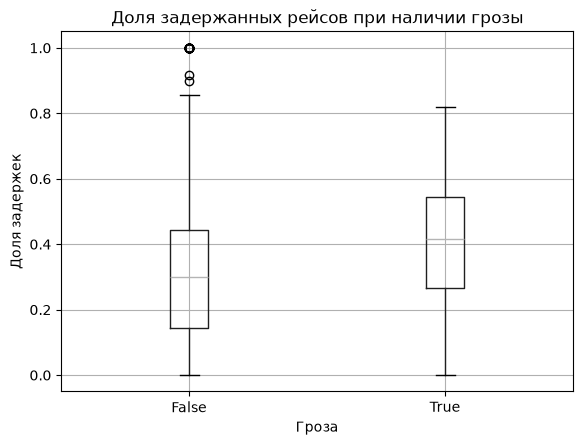

In [15]:
plt.figure(figsize=(8, 6))

weather_df.boxplot(
    column='delay_rate',
    by='has_thunderstorm'
)

plt.title('Доля задержанных рейсов при наличии грозы')
plt.suptitle('')
plt.xlabel('Гроза')
plt.ylabel('Доля задержек')

plt.show()

## Исследовательский анализ данных

In [18]:
query = """
SELECT
    f.flight_key,
    
    CASE
        WHEN f.flight_direction = 'departure'
        THEN f.departure_delay_minutes
        
        WHEN f.flight_direction = 'arrival'
        THEN f.arrival_delay_minutes
    END AS delay_minutes,
    
    w.has_thunderstorm,
    w.is_strong_wind,
    w.is_low_visibility,
    w.is_heavy_precipitation,

    w.wind_category,
    w.visibility_category,
    w.precipitation_category

FROM analytics_core.fact_flights AS f
INNER JOIN analytics_core.fact_weather AS w
ON (
    CASE
        WHEN f.flight_direction = 'departure'
        THEN f.scheduled_departure_utc

        WHEN f.flight_direction = 'arrival'
        THEN f.scheduled_arrival_utc
     END
    )
    
BETWEEN w.weather_time_utc - INTERVAL '30 minutes'
AND w.weather_time_utc + INTERVAL '30 minutes'
"""

flight_weather_df = pd.read_sql(query, engine)
flight_weather_df.head()

,flight_key,delay_minutes,has_thunderstorm,is_strong_wind,is_low_visibility,is_heavy_precipitation,wind_category,visibility_category,precipitation_category
0,7e15c448ecaebb0ead27d3accf078699,-28.0,False,False,False,False,light,excellent,none
1,7e15c448ecaebb0ead27d3accf078699,-28.0,False,False,False,False,light,excellent,none
2,8022b9f840f7991eb236faf57aea3030,0.0,False,False,False,False,light,excellent,none
3,8022b9f840f7991eb236faf57aea3030,0.0,False,False,False,False,light,excellent,none
4,ca0556935d0316771a936a3edd49b551,-19.0,False,False,False,False,calm,excellent,none


### Влияние грозовых явлений на продолжительность задержек рейсов

In [21]:
thunderstorm_group = flight_weather_df.loc[
    (flight_weather_df['has_thunderstorm'] == True)
    &
    (flight_weather_df['delay_minutes'] > 0),
    'delay_minutes'
]
thunderstorm_group.describe()

count    662.000000
mean      33.276435
std       42.074935
min        1.000000
25%       10.000000
50%       22.000000
75%       41.000000
max      489.000000
Name: delay_minutes, dtype: float64

In [22]:
normal_group = flight_weather_df.loc[
    (flight_weather_df['has_thunderstorm'] == False)
    &
    (flight_weather_df['delay_minutes'] > 0),
    'delay_minutes'
]
normal_group.describe()

count    9344.000000
mean       33.472924
std        56.722172
min         1.000000
25%         8.000000
50%        18.000000
75%        37.000000
max       903.000000
Name: delay_minutes, dtype: float64

In [23]:
from scipy.stats import mannwhitneyu

statistic, p_value = mannwhitneyu(
    thunderstorm_group,
    normal_group,
    alternative='two-sided'
)

print(f'p-value: {p_value}, {statistic}')

p-value: 0.0013670452408199997, 3322747.5


In [25]:
n1 = len(thunderstorm_group)
n2 = len(normal_group)

z = (
    statistic - (n1 * n2 / 2)
) / np.sqrt(
    n1 * n2 * (n1 + n2 + 1) / 12
)
print(z)

# размер эффекта
r = abs(z) / np.sqrt(n1 + n2)
print(r)

3.2007449151096456
0.0319978512351974


### Влияние осадков на продолжительность задержек рейсов

In [29]:
precipitation_group = flight_weather_df.loc[
    (flight_weather_df['precipitation_category'] != 'none')
    &
    (flight_weather_df['delay_minutes'] > 0),
    'delay_minutes'
]

normal_precipitation_group = flight_weather_df.loc[
    (flight_weather_df['precipitation_category'] == 'none')
    &
    (flight_weather_df['delay_minutes'] > 0),
    'delay_minutes'
]

In [30]:
statistic, p_value = mannwhitneyu(
    precipitation_group,
    normal_precipitation_group,
    alternative='two-sided'
)

print(statistic)
print(p_value)

9979976.5
4.8443452085212836e-05


In [31]:
n1 = len(precipitation_group)
n2 = len(normal_precipitation_group)
z = (
    statistic - (n1 * n2 / 2)
) / np.sqrt(
    n1 * n2 * (n1 + n2 + 1) / 12
)

r = abs(z) / np.sqrt(n1 + n2)

print(r)

0.04060805685319967


## Построение логистической регрессии

In [33]:
query = """
WITH flights AS (
    SELECT
        flight_key,
        CASE
            WHEN flight_direction = 'departure'
                then scheduled_departure_utc
            WHEN flight_direction = 'arrival'
                then scheduled_arrival_utc
        END AS operation_ts,
        CASE
            WHEN flight_direction = 'departure'
                then departure_delay_minutes
            WHEN flight_direction = 'arrival'
                then arrival_delay_minutes
        END AS delay_minutes
    FROM analytics_core.fact_flights
    WHERE
        (
            flight_direction = 'departure'
            and airport_departure_iata = 'HKT'
        )
        OR
        (
            flight_direction = 'arrival'
            and airport_arrival_iata = 'HKT'
        )
),

weather as (
    SELECT
        weather_time_utc,
        temperature_2m_c,
        relative_humidity_2m_pct,
        precipitation_mm,
        visibility_m,
        cloudcover_pct,
        windspeed_10m_ms,
        has_thunderstorm
    FROM analytics_core.fact_weather
    WHERE airport_iata = 'HKT'
)

SELECT
    f.flight_key,
    f.operation_ts,
    w.weather_time_utc,
    f.delay_minutes,
    w.temperature_2m_c,
    w.relative_humidity_2m_pct,
    w.precipitation_mm,
    w.visibility_m,
    w.cloudcover_pct,
    w.windspeed_10m_ms,
    w.has_thunderstorm
FROM flights AS f
LEFT JOIN weather AS w
ON f.operation_ts BETWEEN w.weather_time_utc - interval '30 minutes'
AND w.weather_time_utc + INTERVAL '30 minutes'
WHERE f.delay_minutes IS NOT NULL;
"""

regression_df = pd.read_sql(query, engine)
regression_df.head()

,flight_key,operation_ts,weather_time_utc,delay_minutes,temperature_2m_c,relative_humidity_2m_pct,precipitation_mm,visibility_m,cloudcover_pct,windspeed_10m_ms,has_thunderstorm
0,7e15c448ecaebb0ead27d3accf078699,2025-12-15 16:30:00+00:00,2025-12-15 16:00:00,-28.0,26.6,84.0,0.0,24140.0,100.0,7.3,False
1,7e15c448ecaebb0ead27d3accf078699,2025-12-15 16:30:00+00:00,2025-12-15 17:00:00,-28.0,26.4,84.0,0.0,24140.0,100.0,7.6,False
2,8022b9f840f7991eb236faf57aea3030,2025-12-16 16:30:00+00:00,2025-12-16 16:00:00,0.0,26.6,83.0,0.0,24140.0,100.0,7.6,False
3,8022b9f840f7991eb236faf57aea3030,2025-12-16 16:30:00+00:00,2025-12-16 17:00:00,0.0,26.3,84.0,0.0,24140.0,100.0,7.8,False
4,ca0556935d0316771a936a3edd49b551,2025-12-17 16:30:00+00:00,2025-12-17 16:00:00,-19.0,26.9,83.0,0.0,24140.0,100.0,2.1,False


In [35]:
regression_df.shape

(17004, 11)

In [34]:
regression_df['flight_key'].nunique()

15631

In [37]:
# Сбрасываем часовые пояса у обеих колонок перед вычитанием
time_diffs = (
    regression_df['operation_ts'].dt.tz_localize(None) - 
    regression_df['weather_time_utc'].dt.tz_localize(None)
)

regression_df['time_diff'] = time_diffs.abs()

In [39]:
# удаления дублей 
regression_df = (
    regression_df
    .sort_values('time_diff')
    .drop_duplicates(
        subset='flight_key',
        keep='first'
    )
)
regression_df.shape

(15631, 12)

In [40]:
regression_df.isna().sum()

flight_key                  0
operation_ts                0
weather_time_utc            0
delay_minutes               0
temperature_2m_c            0
relative_humidity_2m_pct    0
precipitation_mm            0
visibility_m                0
cloudcover_pct              0
windspeed_10m_ms            0
has_thunderstorm            0
time_diff                   0
dtype: int64

In [41]:
# признак задержки рейса
regression_df['delay_flag'] = (regression_df['delay_minutes'] > 10).astype(int)

In [42]:
regression_df['delay_flag'].value_counts()

delay_flag
0    9303
1    6328
Name: count, dtype: int64

In [48]:
# признаки для модели
features = [
    'temperature_2m_c',
    'relative_humidity_2m_pct',
    'precipitation_mm',
    'visibility_m',
    'cloudcover_pct',
    'windspeed_10m_ms',
    'has_thunderstorm'
]

X = regression_df[features]
y = regression_df['delay_flag']

In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [50]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(y_train.shape)
print(y_test.shape)

(12504,)
(3127,)


In [51]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000
)

model.fit(
    X_train_scaled,
    y_train
)

y_pred = model.predict(X_test_scaled)
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(3127,))

In [52]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [53]:
accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

0.5874640230252638


In [54]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.59      0.95      0.73      1834
           1       0.51      0.08      0.13      1293

    accuracy                           0.59      3127
   macro avg       0.55      0.51      0.43      3127
weighted avg       0.56      0.59      0.48      3127



In [55]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[1738,   96],
       [1194,   99]])

In [56]:
coef_df = pd.DataFrame({
    'feature': features,
    'coefficient': model.coef_[0]
}).sort_values('coefficient', ascending=False)

coef_df

,feature,coefficient
3,visibility_m,0.155069
4,cloudcover_pct,0.154330
2,precipitation_mm,0.084084
6,has_thunderstorm,0.076651
5,windspeed_10m_ms,0.045168
0,temperature_2m_c,-0.062224
1,relative_humidity_2m_pct,-0.239135
